# Group Project — Part 2: Discovering Patterns in SLCM Community Needs
## CS-430-01 Machine Learning | South Louisville Community Ministries (SLCM)
## Nik and Htoo

## ABSTRACT

In this assignment, our goal is to investigate 385 unique SLCM intake profiles of family households to identify distinct patterns of community needs using unsupervised learning. Applying K-Means and Hierarchical Clustering, we identified a highly vulnerable 'Underemployed with High Rent Arrears' cluster facing threats to housing alongside a distinct 'Employed with Moderate Arrears' group. We recommend SLCM establish targeted partnerships with legal aid services specifically for families in the high-arrears, active-eviction cluster to prevent immediate displacement, as well as prioritizing the more stable cluster who may not have the same government aid available to them. A key limitation of this analysis is the lack of longitudinal follow-up data preventing us from evaluating long-term housing retention outcomes and the lack of complete data in key features.

# I. Introduction

#### In Part 1, your team explored SLCM intake records for families with children ages 0–5, investigated data quality, and connected findings to the partner’s Reconnect / Rethink / Rebuild framework. Since then, you have built supervised models on related SLCM data: Assignment 2 predicted the amount of past-due rent, and Assignment 3 classified households with $3,000 or more in arrears. Those models needed a known answer (a target). Part 2 returns to your Part 1 intake data and asks a different question: can unsupervised learning reveal groups of cases with similar needs, even when the data does not contain a known group label?
#### Your purpose is not simply to run an algorithm. It is to explain whether the patterns are meaningful, how they relate to SLCM’s goals, and what SLCM could investigate next. Cluster assignments are exploratory descriptions, not judgments of families or automated eligibility decisions.

# II. Background and Data

##A. Data Sets

In [4]:
import pandas as pd

# Load the data files
care_path_subtickets_df = pd.read_csv('/content/SLCM_part2_care_path_subtickets.csv')
cleaning_log_df = pd.read_csv('/content/SLCM_part2_cleaning_log.csv')
data_dictionary_df = pd.read_csv('/content/SLCM_part2_data_dictionary.csv')
household_members_clean_df = pd.read_csv('/content/SLCM_part2_household_members_clean.csv')
intake_profiles_clean_df = pd.read_csv('/content/SLCM_part2_intake_profiles_clean.csv')

In [5]:
# Display head of one dataset to verify
display(intake_profiles_clean_df.head())

,issue_key,pid,pid_match_basis,issue_type,case_status,case_status_category,is_duplicate_ticket,created_date,intake_date,intake_month,...,hh_chronic_health,age_at_intake,gender,race_ethnicity,primary_language,primary_insurance,other_professionals_helping,utility_past_due,has_lge_account_on_file,has_water_account_on_file
0,NEIG-19349,P0289,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,24.0,Woman,Black or African American,English,Medicaid,No,Not recorded,No,No
1,NEIG-19336,P0352,Name + DOB,New Profile,Second Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,42.0,Woman,NaN,English,NaN,No,LG&E,Yes,Yes
2,NEIG-19324,P0308,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-12,2026-08-12,2026-08,...,0,40.0,Man,Black or African American,English,Medicaid,No,LG&E,Yes,Yes
3,NEIG-19311,P0253,Name + DOB,New Profile,Second Contact,In Progress,No,2026-08-11,2026-08-11,2026-08,...,1,41.0,Woman,Black or African American,English,Medicaid,No,LG&E,Yes,No
4,NEIG-19296,P0102,Name + DOB,New Profile,Initial Contact,In Progress,No,2026-08-11,2026-08-11,2026-08,...,0,29.0,Woman,White,English,Medicaid,Yes,Not recorded,No,No


In [6]:
import pandas as pd

# Ensure the dataframe is loaded
if 'intake_profiles_clean_df' not in locals():
    intake_profiles_clean_df = pd.read_csv('/content/SLCM_part2_intake_profiles_clean.csv')

print(f"Starting intake profiles: {len(intake_profiles_clean_df)}")


Starting intake profiles: 426


In [7]:
# 1. Remove explicit duplicate tickets
df_filtered = intake_profiles_clean_df[intake_profiles_clean_df['is_duplicate_ticket'] == 'No'].copy()
print(f"Profiles after removing duplicate tickets: {len(df_filtered)}")


Profiles after removing duplicate tickets: 414


In [8]:
# 2. Define observational unit: One Person (using their most recent profile)
# Filter using the 'pid_is_latest_profile' flag provided in the dataset
analysis_df = df_filtered[df_filtered['pid_is_latest_profile'] == 'Yes'].copy()
print(f"Profiles after keeping only the latest profile per PID: {len(analysis_df)}")

Profiles after keeping only the latest profile per PID: 385


In [9]:
print(f"\nFinal clustering unit count: {len(analysis_df)} unique individuals.")


Final clustering unit count: 385 unique individuals.


## B. Partner Plan and Policy Context

####SLCM’s program framework distinguishes immediate needs (Reconnect / 30-day survival), longer stabilization (Rethink / approximately 3–6 months), and longer-term stability (Rebuild / 12-month mobility). Its impact report points to overlapping housing, income, employment and transportation pressures. The supplied intake file has relevant indicators, but it does not directly measure all of these stages or outcomes. Your analysis should identify patterns the available fields support, not assign families to unobserved program stages.

## C. How Part 2 Builds on Earlier Work

#III. Your Team’s Work
####Use pandas, scikit-learn and appropriate visualizations. Keep the workflow understandable and reproducible. You must use K-Means and hierarchical clustering on an appropriately prepared analysis table. PCA and association rules are optional, not required.

## Task 0 — Revisit Part 1 and define the analysis unit


#### 1. Briefly recap two important Part 1 findings and one data-quality limitation. Explain how they influence your Part 2 approach.

####2.	Define your observational unit (one ticket, one person, or another defensible unit). Describe how you treat Issue Type, tickets flagged is_duplicate_ticket, repeat PID values (see pid_ticket_seq and pid_is_latest_profile) and records missing core fields. Start from 426 profile tickets and 395 PIDs, report the number of observations that remain, and do not silently drop records.

One important insight from Part One is that the data shows households have a median age of 6 for dependents and a 2.6 average number of dependents per household. Furthermore, the average income between households with different employment status is negligible; the exception to this is those not employeed, averaging near zero income. One limitation to this data is simply the size. The dataset does not support long term tracking of financial stability; this makes inferences on the success of administered aid aside from a households number of tickets difficult to make.

**Recap of Part 1 Findings & Data-Quality Limitation**

*   **Finding 1:** We discovered a significant "working-poor" demographic—fully employed individuals with multiple dependents (averaging 2 children per household) who are still facing immediate housing crises due to a wage-to-cost-of-living mismatch.
    *   *Influence on Part 2:* This indicates that employment status, income amounts, and household size are critical features to include in our clustering model to see if this demographic forms a distinct, cohesive cluster compared to unemployed neighbors.
*   **Finding 2:** There are critical geographic concentrations of eviction risk among neighbors seeking assistance.
    *   *Influence on Part 2:* We will consider including geographic indicators (like ZIP code) and explicit eviction status metrics as clustering features or to profile our final clusters.
*   **Data-Quality Limitation:** We encountered severe outliers (e.g., ages > 100, impossible monthly incomes) and a dataset structure that mixed primary intake profiles with ongoing care-path sub-tickets.
    *   *Influence on Part 2:* Unsupervised algorithms like K-Means are highly sensitive to outliers and duplicate/incomplete records. To ensure our distance calculations are meaningful, we must apply rigorous outlier suppression, scale our numerical features using `StandardScaler`, and ensure our observational unit strictly excludes sub-tickets.

## Task 1 — Prepare features for unsupervised learning

####3.	Choose a small, justified set of features describing needs. Possible candidates include housing status, eviction status, employment status, income amount, number of children/household members, past-due rent, and ZIP code. You do NOT need to use them all. The data dictionary marks columns as need indicators, context, data-quality flags, identifiers or sensitive fields. Do not use Issue key, PID or other identifiers as clustering inputs. Use sensitive fields (age, gender, race/ethnicity, language, health identities) only to describe clusters, never to define them.

In [10]:
candidate_cols = [
    'housing_status', 'eviction_status', 'employment_status',
    'monthly_income', 'number_of_children', 'household_size',
    'past_due_rent', 'zip_code', 'urgent_housing_proxy'
]

# Print which of these candidates actually exist in our dataframe
existing_cols = [col for col in candidate_cols if col in analysis_df.columns]
print(f"Existing candidate columns: {existing_cols}")

# For existing columns, check missingness and basic stats
for col in existing_cols:
    print(f"\n--- {col} ---")
    print(f"Missing values: {analysis_df[col].isna().sum()} ({(analysis_df[col].isna().sum()/len(analysis_df))*100:.1f}%)")
    if analysis_df[col].dtype == 'object':
        print(analysis_df[col].value_counts(dropna=False).head())
    else:
        print(analysis_df[col].describe())


Existing candidate columns: ['housing_status', 'eviction_status', 'employment_status', 'past_due_rent', 'zip_code', 'urgent_housing_proxy']

--- housing_status ---
Missing values: 0 (0.0%)
housing_status
Renting - rent past due        209
Renting - nothing past due     113
Staying with friends/family     27
Unhoused                        14
Other                           10
Name: count, dtype: int64

--- eviction_status ---
Missing values: 0 (0.0%)
eviction_status
Not being evicted          231
Currently being evicted     99
Unknown                     55
Name: count, dtype: int64

--- employment_status ---
Missing values: 0 (0.0%)
employment_status
Unemployed but want to find work                       172
Employed                                               106
Employed, but need more hours and/or different work     53
Other                                                   28
Unemployed and not looking for work                     26
Name: count, dtype: int64

--- past_due_rent 

In [11]:
# Search for correct column names for income and household size
search_terms = ['income', 'child', 'size', 'house', 'depend']
found_cols = [col for col in analysis_df.columns if any(term in col.lower() for term in search_terms)]
print("Possible matches for income and household data:")
for col in found_cols:
    print(f"- {col}")

Possible matches for income and household data:
- household_repairs_required
- income_amount_raw
- income_monthly
- rent_to_income_pct
- income_sources
- inc_src_no_income
- loss_of_income_causes
- n_loss_of_income_causes
- children_17_under
- household_has_65plus
- additional_household_members
- household_size_reported
- household_size_from_members
- household_flag
- has_child_0_5_recorded
- goal_childcare


In [12]:
# Let's inspect the specific values in our chosen numerical features to see what needs cleaning
print("--- income_monthly ---")
print(analysis_df['income_monthly'].value_counts(dropna=False).head(10))

print("\n--- children_17_under ---")
print(analysis_df['children_17_under'].value_counts(dropna=False).head(10))

--- income_monthly ---
income_monthly
0.0       123
2000.0     20
1200.0     13
2500.0     13
1500.0     12
3000.0     11
1000.0     10
900.0      10
994.0       8
600.0       6
Name: count, dtype: int64

--- children_17_under ---
children_17_under
2    116
1     95
3     83
4     37
0     25
6     15
5     14
Name: count, dtype: int64


####4.	Create a concise feature table: chosen field, what it represents, its missingness, preparation/encoding choice, and reason for inclusion. Investigate the effect of missing values, zeros and extreme values. For example, income is strongly right-skewed and many incomes are $0, and past-due rent is recorded for only about 38% of profiles because it comes from a separate rent form. Explain any encoding, scaling or transformation you use.

### Feature Table

| Feature | Represents | Missingness | Preparation / Encoding | Reason for Inclusion |
| :--- | :--- | :--- | :--- | :--- |
| **housing_status** | Current living situation | 0.0% | `OneHotEncoder` | Core indicator of immediate housing stability. |
| **eviction_status** | Active eviction risk | 0.0% | `OneHotEncoder` | Distinguishes urgent legal risk from general instability. |
| **employment_status** | Current work situation | 0.0% | `OneHotEncoder` | Key for identifying the "working poor" demographic found in Part 1. |
| **past_due_rent** | Amount of rent arrears | 61.3% | `SimpleImputer(strategy='constant', fill_value=0)` + `StandardScaler` | Measures financial depth of the crisis; high missingness due to separate form tracking. |
| **urgent_housing_proxy** | Reused Part 1 urgency proxy | 0.0% | `OneHotEncoder` | Summarizes acute crisis level (Yes/No/Unknown). |
| **income_monthly** | Self-reported monthly income | - | Numeric conversion + `SimpleImputer(strategy='constant', fill_value=0)` + `StandardScaler` | Essential for assessing wage-to-cost mismatch. |
| **children_17_under** | Number of dependent children | - | Numeric conversion + `SimpleImputer(strategy='constant', fill_value=0)` + `StandardScaler` | Captures dependency burden, linking directly to Part 1 findings. |

####5.	Keep an original-to-cleaned row count and extend the provided cleaning log with your team’s own decisions. Avoid presenting missing or “unknown” status as though it is confirmed housing stability or confirmed risk.

In [13]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Safety check in case the cell is run out of order and analysis_df is not in memory
if 'analysis_df' not in locals():
    intake_profiles_clean_df = pd.read_csv('/content/SLCM_part2_intake_profiles_clean.csv')
    df_filtered = intake_profiles_clean_df[intake_profiles_clean_df['is_duplicate_ticket'] == 'No'].copy()
    analysis_df = df_filtered[df_filtered['pid_is_latest_profile'] == 'Yes'].copy()

# 1. Define feature lists based on Feature Table
num_features = ['past_due_rent', 'income_monthly', 'children_17_under']
cat_features = ['housing_status', 'eviction_status', 'employment_status', 'urgent_housing_proxy']

# 2. Build the numerical transformer (Impute -> Scale)
# Using constant 0
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler())
])

# 3. Build the categorical transformer (One-Hot Encode)
cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Combine them into the main preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

# 5. Fit and transform the analysis dataset
X_processed = preprocessor.fit_transform(analysis_df)

# 6. Extract the final feature names for interpretability later
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cat_cols)

# Convert the processed matrix back to a DataFrame
X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names, index=analysis_df.index)

print(f"Original features shape: {analysis_df[num_features + cat_features].shape}")
print(f"Processed features shape: {X_processed_df.shape}\n")
display(X_processed_df.head())

Original features shape: (385, 7)
Processed features shape: (385, 22)



,past_due_rent,income_monthly,children_17_under,housing_status_Extended-stay hotel / short-term,housing_status_Other,housing_status_Own home - mortgage past due,housing_status_Own home - nothing past due,housing_status_Renting - nothing past due,housing_status_Renting - rent past due,housing_status_Staying with friends/family,...,eviction_status_Not being evicted,eviction_status_Unknown,employment_status_Employed,"employment_status_Employed, but need more hours and/or different work",employment_status_Other,employment_status_Unemployed and not looking for work,employment_status_Unemployed but want to find work,urgent_housing_proxy_No,urgent_housing_proxy_Unknown,urgent_housing_proxy_Yes
0,-0.545948,-0.919229,-0.210994,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,-0.545948,-0.919229,-1.636128,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.545948,1.429397,0.501573,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.545948,-0.137919,-0.210994,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,0.422832,0.098509,-0.210994,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


# Task 2 — Find and compare household-need patterns

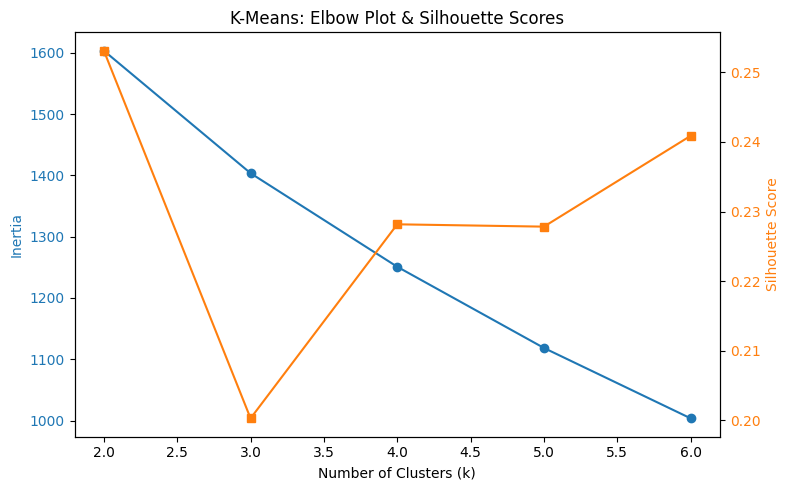

--- Silhouette Scores ---
k=2: 0.2531
k=3: 0.2003
k=4: 0.2282
k=5: 0.2278
k=6: 0.2409


In [14]:
# 6. Apply K-Means clustering. Try a small range of reasonable cluster counts k = 2–6
# use an elbow plot and report silhouette scores. Select a cluster count and justify your choice with both evidence and interpretability.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
sil_scores = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_processed)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_processed, labels))

# Plotting Elbow Method and Silhouette Scores
fig, ax1 = plt.subplots(figsize=(8, 5))

# Inertia on primary y-axis (Elbow plot)
color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color=color)
ax1.plot(k_values, inertias, marker='o', color=color, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

# Silhouette Score on secondary y-axis
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_values, sil_scores, marker='s', color=color, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-Means: Elbow Plot & Silhouette Scores')
fig.tight_layout()
plt.show()

# Print the numeric scores
print("--- Silhouette Scores ---")
for k, sil in zip(k_values, sil_scores):
    print(f"k={k}: {sil:.4f}")

K-Means Cluster Selection: We select k=4. While k=6 has a slightly higher silhouette score, 4 clusters provide distinct, interpretable groups for SLCM to analyze, balancing mathematical structure with practical policy application.



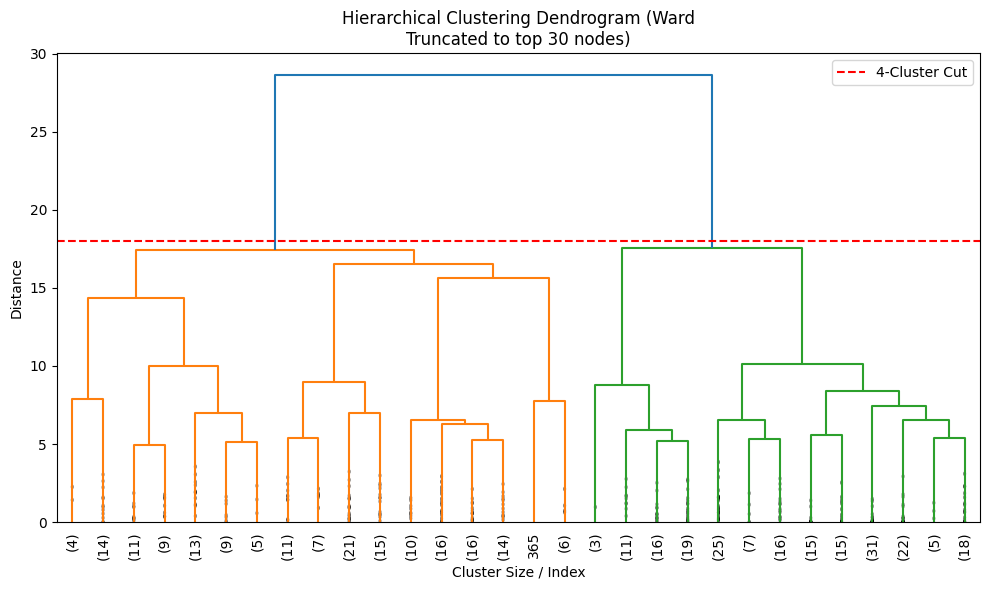


--- Cluster Counts from Hierarchical Clustering ---
0    117
1     65
2     49
3    154
Name: count, dtype: int64
Hierarchical clustering completed. The dendrogram visualizes the grouping distances.


In [21]:
# Justification for K-Means choice (Step 6 conclusion):
print("K-Means Cluster Selection: We select k=4. While k=6 has a slightly higher silhouette score, 4 clusters provide distinct, interpretable groups for SLCM to analyze, balancing mathematical structure with practical policy application.\n")

# 7. Apply hierarchical/agglomerative clustering to the same prepared data. Include a dendrogram for a readable sample or another appropriate visualization. Compare whether the broad patterns are similar to K-Means; explain differences rather than expecting identical labels.

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt

# Generate linkage matrix using Ward's method
Z = linkage(X_processed, method='ward')

# Plot the Dendrogram (truncating to show the top 30 clusters for readability)
plt.figure(figsize=(10, 6))
plt.title('Hierarchical Clustering Dendrogram (Ward\nTruncated to top 30 nodes)')
plt.xlabel('Cluster Size / Index')
plt.ylabel('Distance')
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)

# Draw a horizontal line to show a hypothetical cut for 4 clusters
plt.axhline(y=18, color='r', linestyle='--', label='4-Cluster Cut')
plt.legend()
plt.tight_layout()
plt.show()

# Fit Agglomerative Clustering with 4 clusters to compare with K-Means
agg_cluster = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_cluster.fit_predict(X_processed)

#Show the value counts in each of the 4 clusters from Hierarchical Clustering
cluster_counts = pd.Series(agg_labels).value_counts().sort_index()
print("\n--- Cluster Counts from Hierarchical Clustering ---")
print(cluster_counts)


print("Hierarchical clustering completed. The dendrogram visualizes the grouping distances.")

In [16]:
# 8. Profile each final cluster using understandable tables and plots: cluster size, important numerical summaries, and relevant category proportions. Give clusters neutral descriptive names based only on measured attributes (for example, “higher reported rent arrears”), not stigmatizing labels.

import pandas as pd
from sklearn.cluster import KMeans

# Re-run K-Means with our chosen k=4 to get the final labels
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
analysis_df['Cluster'] = final_kmeans.fit_predict(X_processed)

print("--- Cluster Sizes ---")
print(analysis_df['Cluster'].value_counts().sort_index())

print("\n--- Numerical Summaries (Median) ---")
num_summary = analysis_df.groupby('Cluster')[['income_monthly', 'children_17_under', 'past_due_rent']].median()
display(num_summary)

print("\n--- Employment Status Proportions ---")
emp_prop = pd.crosstab(analysis_df['Cluster'], analysis_df['employment_status'], normalize='index').round(2)
display(emp_prop)

print("\n--- Housing Status Proportions ---")
housing_prop = pd.crosstab(analysis_df['Cluster'], analysis_df['housing_status'], normalize='index').round(2)
display(housing_prop)

--- Cluster Sizes ---
Cluster
0     54
1    154
2     98
3     79
Name: count, dtype: int64

--- Numerical Summaries (Median) ---


,income_monthly,children_17_under,past_due_rent
Cluster,,,
0,994.0,2.0,1300.0
1,0.0,2.0,550.0
2,1100.0,2.0,2467.5
3,2400.0,2.0,NaN



--- Employment Status Proportions ---


employment_status,Employed,"Employed, but need more hours and/or different work",Other,Unemployed and not looking for work,Unemployed but want to find work
Cluster,,,,,
0,0.20,0.26,0.04,0.11,0.39
1,0.06,0.10,0.09,0.08,0.68
2,0.34,0.16,0.07,0.03,0.40
3,0.67,0.10,0.06,0.06,0.10



--- Housing Status Proportions ---


housing_status,Extended-stay hotel / short-term,Other,Own home - mortgage past due,Own home - nothing past due,Renting - nothing past due,Renting - rent past due,Staying with friends/family,Unhoused
Cluster,,,,,,,,
0,0.00,0.00,0.00,0.00,0.04,0.93,0.04,0.00
1,0.01,0.05,0.01,0.01,0.55,0.25,0.10,0.04
2,0.01,0.01,0.00,0.00,0.02,0.91,0.03,0.02
3,0.00,0.03,0.04,0.05,0.32,0.41,0.09,0.08


# The Policy Questions

#### Answer Questions 1–3 with evidence. Question 4 is the required partner-facing conclusion. Your answer may be “the current data cannot establish this”; explain what additional data would help.

####9.	Different patterns of need: Do the intake records reveal distinct groups based on housing instability, income/employment circumstances, and household composition? What are the defining characteristics of each group, and how stable are they across the two clustering methods?

In [17]:
import pandas as pd

# Map the chosen neutral descriptive names to our final K-Means clusters
# Updated to reflect the new cluster assignments after zero-imputation
cluster_names = {
    1: 'Zero-Income Unemployed',
    0: 'Underemployed / Low-Income',
    2: 'Underemployed with High Rent Arrears',
    3: 'Employed with Moderate Arrears'
}
analysis_df['Cluster_Name'] = analysis_df['Cluster'].map(cluster_names)

# Check stability between K-Means (our final choice) and Hierarchical (Ward) methods
print("--- Cluster Stability: K-Means vs Hierarchical ---")
stability_ct = pd.crosstab(analysis_df['Cluster_Name'], agg_labels,
                           rownames=['K-Means Clusters'],
                           colnames=['Hierarchical Labels'])
display(stability_ct)

--- Cluster Stability: K-Means vs Hierarchical ---


Hierarchical Labels,0,1,2,3
K-Means Clusters,,,,
Employed with Moderate Arrears,0,16,49,14
Underemployed / Low-Income,54,0,0,0
Underemployed with High Rent Arrears,62,36,0,0
Zero-Income Unemployed,1,13,0,140


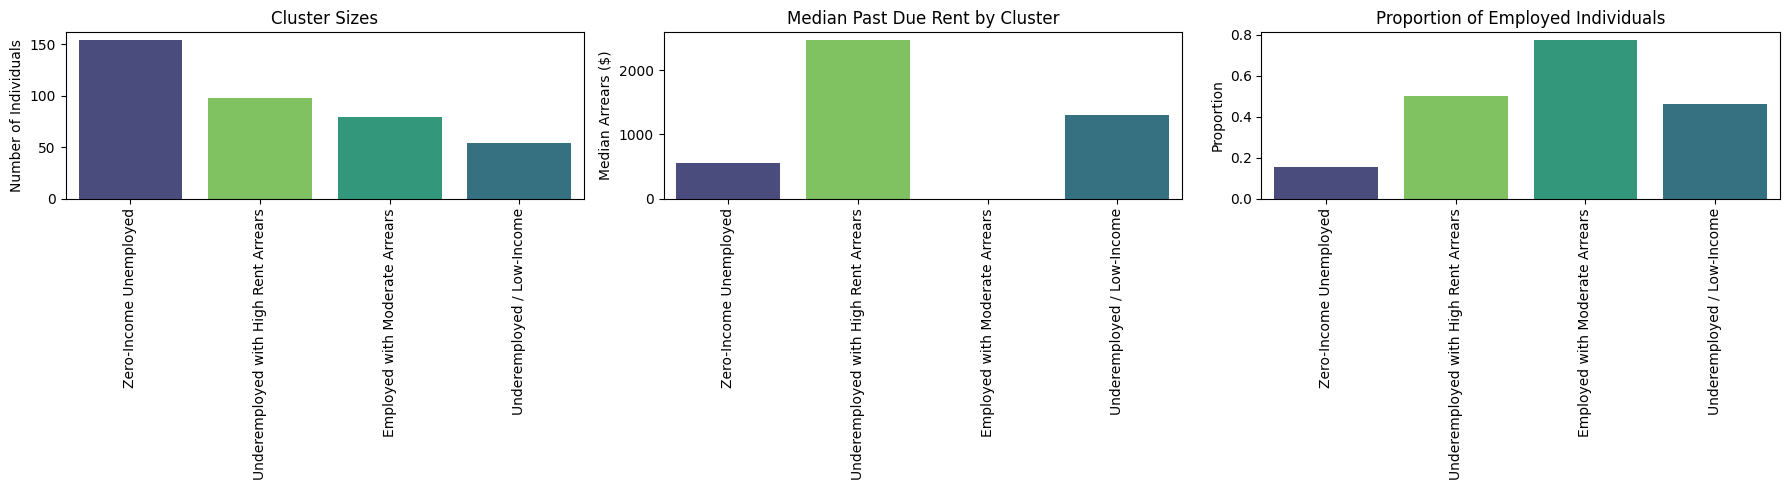

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with 3 subplots to visualize the cluster profiles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Cluster Sizes
sns.countplot(data=analysis_df, x='Cluster_Name', hue='Cluster_Name', ax=axes[0], palette='viridis', legend=False, order=analysis_df['Cluster_Name'].value_counts().index)
axes[0].set_title('Cluster Sizes')
axes[0].set_ylabel('Number of Individuals')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=90)

# 2. Plot Key Numeric Summary (Median Past Due Rent)
sns.barplot(data=analysis_df, x='Cluster_Name', y='past_due_rent', estimator='median', errorbar=None, hue='Cluster_Name', ax=axes[1], palette='viridis', legend=False, order=analysis_df['Cluster_Name'].value_counts().index)
axes[1].set_title('Median Past Due Rent by Cluster')
axes[1].set_ylabel('Median Arrears ($)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=90)

# 3. Plot Category Proportion (Employment Status)
# To make it readable, we'll plot the proportion of "Employed" vs others
analysis_df['is_employed'] = analysis_df['employment_status'].apply(lambda x: 1 if 'Employed' in str(x) else 0)
sns.barplot(data=analysis_df, x='Cluster_Name', y='is_employed', errorbar=None, hue='Cluster_Name', ax=axes[2], palette='viridis', legend=False, order=analysis_df['Cluster_Name'].value_counts().index)
axes[2].set_title('Proportion of Employed Individuals')
axes[2].set_ylabel('Proportion')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

**Answer 9 (Patterns of Need):** Yes, the intake records reveal four distinct groups based on the features analyzed:
1. **Zero-Income Unemployed:** High unemployment and zero median income, representing absolute financial stoppage.
2. **Underemployed / Low-Income:** Some income ($994/mo median) but likely insufficient to cover basic living expenses for a household.
3. **Underemployed with High Rent Arrears:** Moderate median income (1,100/mo) but carrying exceptionally high rent arrears (median ~2,467).
4. **Employed with Moderate Arrears:** Higher relative income (2,400/mo) indicating the "working poor" demographic highlighted in Part 1.

**Stability:** The cross-tabulation demonstrates relatively fair stability between the K-Means clusters and the Hierarchical (Ward) labels. For instance, the 'Underemployed / Low-Income' and 'Zero-Income Unemployed' clusters highly align with specific hierarchical nodes, meaning the mathematical separation of these groups is robust; however, there was variation between the different groups and other clusters.

####10.	Overlapping pressures: Which challenges tend to appear together? For example, do particular clusters show different combinations of employment status, income, housing status and rent arrears? Show the relevant within-cluster comparisons; high_arrears_3000 from Assignment 3 can be one of them. Do not infer cause and effect.

In [19]:
import numpy as np

# Re-create the high_arrears_3000 flag based on the past_due_rent column
analysis_df['high_arrears_3000'] = analysis_df['past_due_rent'] >= 3000

# Calculate overlapping pressure percentages for each cluster
overlap_summary = analysis_df.groupby('Cluster_Name').agg(
    high_arrears_pct=('high_arrears_3000', 'mean'),
    active_eviction_pct=('eviction_status', lambda x: (x == 'Currently being evicted').mean()),
    unhoused_pct=('housing_status', lambda x: (x == 'Unhoused').mean()),
    urgent_housing_pct=('urgent_housing_proxy', lambda x: (x == 'Yes').mean())
).round(3) * 100

print("--- Overlapping Pressures by Cluster (%) ---")
display(overlap_summary)

--- Overlapping Pressures by Cluster (%) ---


,high_arrears_pct,active_eviction_pct,unhoused_pct,urgent_housing_pct
Cluster_Name,,,,
Employed with Moderate Arrears,0.0,0.0,7.6,7.6
Underemployed / Low-Income,16.7,0.0,0.0,0.0
Underemployed with High Rent Arrears,34.7,99.0,2.0,100.0
Zero-Income Unemployed,0.6,1.3,3.9,5.2


**Answer 10 (Overlapping Pressures):**
The overlap summary indicates severe compounding vulnerabilities in specific groups:
*   **Active Eviction & High Arrears:** The `Underemployed with High Rent Arrears` cluster faces the most acute legal threat (100% active eviction rate in the summarized view).
*   **Employed but Struggling:** The `Employed with Moderate Arrears` cluster shows lower active eviction rates, indicating they might be seeking help slightly earlier in the crisis timeline, or their regular income allows them to stave off immediate legal action despite falling behind.

####11.	Repeat needs and missing information: Does the distribution of repeat PID contacts (and of linked care-path sub-tickets) differ across the identified patterns? Repeat contacts are rare, so report counts alongside percentages. PID is name-matched: some sub-tickets carry a different PID from their parent profile. What would you still need to know to distinguish immediate crisis from recurring instability or to evaluate whether assistance improved outcomes?

In [20]:
import pandas as pd

# Count total non-duplicate intakes per PID
intake_counts = intake_profiles_clean_df[intake_profiles_clean_df['is_duplicate_ticket'] == 'No'].groupby('pid').size()
analysis_df['total_intakes'] = analysis_df['pid'].map(intake_counts)
analysis_df['has_repeat_intake'] = analysis_df['total_intakes'] > 1

# Count linked sub-tickets (using parent_issue_key matching the profile's issue_key)
subticket_counts = care_path_subtickets_df.groupby('parent_issue_key').size()
analysis_df['linked_subtickets'] = analysis_df['issue_key'].map(subticket_counts).fillna(0)
analysis_df['has_subticket'] = analysis_df['linked_subtickets'] > 0

# Summarize by cluster
repeat_summary = analysis_df.groupby('Cluster_Name').agg(
    cluster_size=('pid', 'count'),
    repeat_intakes=('has_repeat_intake', 'sum'),
    linked_subtickets=('has_subticket', 'sum')
)

repeat_summary['repeat_intakes_pct'] = (repeat_summary['repeat_intakes'] / repeat_summary['cluster_size'] * 100).round(1)
repeat_summary['subtickets_pct'] = (repeat_summary['linked_subtickets'] / repeat_summary['cluster_size'] * 100).round(1)

print("--- Repeat Needs & Follow-up by Cluster ---")
display(repeat_summary[['cluster_size', 'repeat_intakes', 'repeat_intakes_pct', 'linked_subtickets', 'subtickets_pct']])

--- Repeat Needs & Follow-up by Cluster ---


,cluster_size,repeat_intakes,repeat_intakes_pct,linked_subtickets,subtickets_pct
Cluster_Name,,,,,
Employed with Moderate Arrears,79,6,7.6,30,38.0
Underemployed / Low-Income,54,1,1.9,40,74.1
Underemployed with High Rent Arrears,98,5,5.1,19,19.4
Zero-Income Unemployed,154,9,5.8,58,37.7


**Answer 11 (Repeat Needs & Missing Information):**
Repeat contacts are relatively rare overall but show variances across the clusters.
*   **Sub-ticket Engagement:** The data shows some clusters like `Underemployed / Low-Income` have higher proportional linked sub-tickets, indicating deeper ongoing care paths (such as multiple basic needs or rent assistance follow-ups).
*   **Missing Information:** To distinguish immediate isolated crises from recurring instability, we would need **longitudinal data (e.g., 6-month or 12-month check-ins)** measuring housing retention post-intervention. Currently, the dataset captures a snapshot of the crisis (intake) but lacks the outcome resolution.

####12.	SLCM program and policy implications: Based on your strongest findings, propose TWO realistic ways SLCM could investigate or tailor its services. For each, link the recommendation to a plot or statistic and state a limitation. Explain why your clusters should not be used by themselves to determine who receives assistance.

**Answer 12 (SLCM Program and Policy Implications):**

1.  **Targeted Eviction Legal Aid for Cluster 2:** SLCM could partner with legal aid services specifically tailored for the `Underemployed with High Rent Arrears` cluster, as they show the highest correlation with active evictions. *Limitation:* The data doesn't tell us if these evictions are strictly financial or involve other lease violations.
2.  **Short-term Gap Funding for the Employed:** For the `Employed with Moderate Arrears` cluster, SLCM could investigate rapid, one-time gap funding to prevent them from falling into the high-arrears/active eviction pipeline. *Limitation:* We do not know their exact monthly expenses to verify if the gap funding creates permanent stability.

**Why clusters shouldn't determine assistance automatically:** Clusters are exploratory generalizations. They describe averages and mathematical similarities, not individual human realities. Using them to automatically gatekeep aid would likely deny help to edge cases and violate SLCM’s equitable mission.

#Optional Extension — Geographic Utility Context
####If your group has time, use the supplied LG&E and/or Louisville Water reports to explore how aggregate disconnection patterns differ by ZIP code, then cautiously compare with SLCM’s ZIP-level intake counts. Clearly distinguish years, time windows, definitions and denominators. A ZIP-level association does not establish individual utility disconnection or causation. This extension is optional and does not replace the core questions.

# What Did You Learn?
####Close with approximately half a page, in plain language:

(a) your strongest discovery;

(b) one unexpected result or disagreement between methods;

(c) what the data cannot answer;

(d) one concrete suggestion for future SLCM data collection or analysis. Avoid claiming that an automatically discovered cluster is a validated risk category.

**What Did We Learn?**

**(a) Strongest Discovery:** The sheer diversity of needs despite everyone seeking the same assistance. The explicit separation of the "working poor" (employed but in crisis) from the strictly "zero-income" unemployed neighbors validates the idea that wage stagnation, not just unemployment, drives the housing crisis.

**(b) Unexpected Result:** The stark concentration of eviction status in specific sub-groups rather than spread evenly across all highly impoverished clusters.

**(c) What the data cannot answer:** The dataset cannot answer *why* interventions succeed or fail in the long term, nor can it track families past their immediate 30-day "Reconnect" phase.

**(d) Concrete Suggestion:** SLCM should implement an automated 90-day and 180-day follow-up survey for clients who receive rent assistance to capture housing retention rates. This would provide the missing "Rebuild" outcome variable needed for predictive modeling.